# Training Basics: Fitting an Image with a Neural Network

**Author:** Nassim Razaaly ([nassim.razaaly@ensma.fr](mailto:nassim.razaaly@ensma.fr))<br>
**First version:** October 15, 2026<br>
**Last updated:** October 15, 2026

Follow-up of the *PyTorch Tutorial* notebook.

**The problem.** A black-and-white image is a function

$$f : [-1, 1]^2 \to [0, 1], \qquad (x, y) \mapsto \text{gray level of the pixel at position } (x, y)$$

(0 = black, 1 = white). We only know $f$ at the pixels. We approximate it by an MLP $f_{\boldsymbol{\omega}}$, where $\boldsymbol{\omega}$ is the vector of all its parameters (weight matrices and biases). **Training** means finding $\boldsymbol{\omega}$ such that $f_{\boldsymbol{\omega}}(x, y) \approx f(x, y)$, by minimizing the mean squared error over the $N$ training pixels:

$$L(\boldsymbol{\omega}) = \frac{1}{N}\sum_{k=1}^{N} \left(f_{\boldsymbol{\omega}}(x_k, y_k) - f(x_k, y_k)\right)^2$$

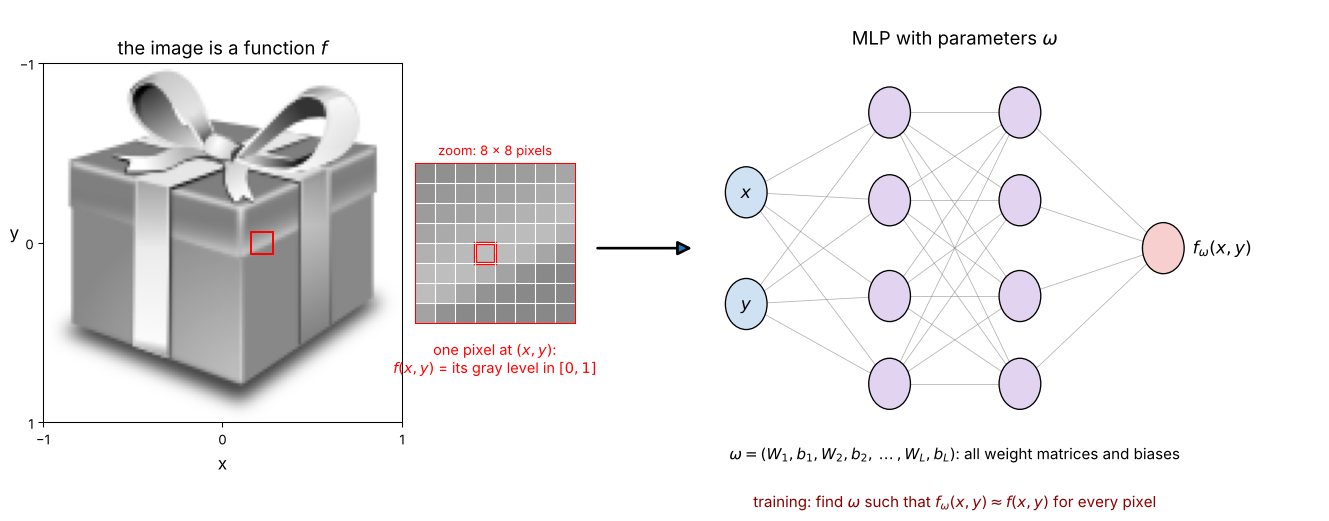

**Contents:**

1. **Data:** a simple image, normalization, training / validation / test sets.
2. **Model and first trainings:** an `MLP` class, and the training loop written in full, with Adam then with L-BFGS.
3. **Toolbox:** the same loop as a reusable function.
4. **Experiments:** normalization, batch size, learning rate, points per epoch, depth, BatchNorm, Dropout, optimizers (Adam, AdamW, L-BFGS), color.
5. **Going further: Fourier features**, for simple and detailed images.
6. **Training to the end:** best settings, learning rate schedule and early stopping, on the color image.
7. **Summary:** the ready-to-use toolbox in one cell.

> **Colab:** *File → Save a copy in Drive* first. Runs on CPU in about 15 minutes; a GPU (*Runtime → Change runtime type*) makes it much faster.

**Dependencies:** `torch>=2.0`, `numpy`, `matplotlib`, `tqdm` (all preinstalled on Colab). The images are shipped with `matplotlib`: no download needed.

In [ ]:
# Outside Colab only:
# !pip install "torch>=2.0" numpy matplotlib tqdm

import copy                                  # to save the best weights (section 6)
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cbook                 # access to matplotlib's sample images
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm                   # progress bars

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

In [ ]:
# @title Plotting helpers (run this cell)
def show_images(images, titles, size=3):
    # gray images: 2D arrays; color images: (n, n, 3) arrays
    fig, ax = plt.subplots(1, len(images), figsize=(size * len(images), size))
    ax = np.atleast_1d(ax)
    for a, im, ti in zip(ax, images, titles):
        a.imshow(np.clip(im, 0, 1), cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=1)
        a.set_title(ti, fontsize=10); a.axis("off")
    plt.tight_layout(); plt.show()

def plot_histories(histories, x="epoch", title=""):
    # histories: {name: history}. One color per run; solid = train, dashed = validation.
    plt.figure(figsize=(8, 4))
    for k, (name, h) in enumerate(histories.items()):
        plt.plot(h[x], h["train"], "-", color=f"C{k}", label=f"{name}: train")
        plt.plot(h[x], h["val"], "--", color=f"C{k}", label=f"{name}: validation")
    plt.yscale("log"); plt.xlabel("time (s)" if x == "time" else x); plt.ylabel("MSE")
    plt.title(title); plt.legend(fontsize=8); plt.show()

## 1. Data

### 1.1 The image

A simple drawing of $128 \times 128$ pixels, shipped with `matplotlib`. It has a transparent background (4th channel, *alpha*): we put it on a white background. We start in black and white (mean of $r, g, b$); color comes in section 4.8.

In [ ]:
rgba = plt.imread(cbook.get_sample_data("Minduka_Present_Blue_Pack.png"))   # (128, 128, 4), in [0, 1]
rgba = torch.tensor(rgba)
img_color = rgba[..., :3] * rgba[..., 3:] + (1 - rgba[..., 3:])             # on a white background
img = img_color.mean(dim=2)                                                  # black and white
n = img.shape[0]

print("color:", tuple(img_color.shape), "| gray:", tuple(img.shape))
show_images([img_color.numpy(), img.numpy()], ["color", "black and white"])

### 1.2 Samples and normalization

Each pixel is one sample: **input** its position, **output** its intensity. That gives $128^2 = 16\,384$ samples.

**Normalization.** Networks train best when inputs and outputs are of order 1 (the initial weights and the learning rate assume this scale). So:

* the pixel of row $i$ and column $j$ ($i, j \in \{0, \dots, 127\}$) gets the coordinates $x = 2\,\frac{j}{n - 1} - 1$ and $y = 2\,\frac{i}{n - 1} - 1$, both in $[-1, 1]$ ($x$ increases to the right, $y$ downwards, as in the image);
* the intensities are kept in $[0, 1]$ (an image file usually stores them in $[0, 255]$: divide by 255).

Section 4.1 shows what happens without normalization.

In [ ]:
ii, jj = torch.meshgrid(torch.arange(n), torch.arange(n), indexing="ij")    # row i, column j
pix = torch.stack([jj.flatten(), ii.flatten()], dim=1).float()               # (16384, 2), in [0, 127]

X = 2 * pix / (n - 1) - 1                     # normalized inputs, in [-1, 1]
Y = img.flatten()[:, None]                    # outputs, in [0, 1], shape (16384, 1)
print("X:", tuple(X.shape), "in", (X.min().item(), X.max().item()))
print("Y:", tuple(Y.shape), "in", (Y.min().item(), Y.max().item()))

### 1.3 Training, validation and test sets

The pixels are split **at random** into three sets:

* **training (60 %)**: used to update the weights;
* **validation (20 %)**: used to monitor training and to choose the settings (learning rate, network size, ...);
* **test (20 %)**: used once, at the very end, to measure the error on unseen pixels.

The model never sees the validation and test pixels: it must fill them in from their neighbors.

In [ ]:
torch.manual_seed(0)
perm = torch.randperm(n * n)
n_train, n_val = int(0.6 * n * n), int(0.2 * n * n)
train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]

X_train, Y_train = X[train_idx].to(device), Y[train_idx].to(device)
X_val, Y_val = X[val_idx].to(device), Y[val_idx].to(device)
X_test, Y_test = X[test_idx].to(device), Y[test_idx].to(device)
X_all = X.to(device)                          # all pixels: to draw the predicted image
print("train:", len(train_idx), "| validation:", len(val_idx), "| test:", len(test_idx))

# where are the pixels of each set?
split = torch.zeros(n * n, 3)
split[train_idx] = torch.tensor([0.12, 0.47, 0.71])    # blue
split[val_idx] = torch.tensor([1.0, 0.5, 0.05])        # orange
split[test_idx] = torch.tensor([0.17, 0.63, 0.17])     # green
show_images([split.reshape(n, n, 3).numpy()],
            ["train (blue), validation (orange), test (green)"], size=4)

What each set contains (the other pixels are shown in light blue):

In [ ]:
def show_set(idx):
    im = torch.tensor([0.75, 0.85, 1.0]).repeat(n * n, 1)      # light blue background
    im[idx] = img.flatten()[idx, None].repeat(1, 3)             # gray level of the pixels of the set
    return im.reshape(n, n, 3).numpy()

show_images([show_set(train_idx), show_set(val_idx), show_set(test_idx)],
            [f"training set ({len(train_idx)} pixels)", f"validation set ({len(val_idx)} pixels)",
             f"test set ({len(test_idx)} pixels)"], size=4)

**Image quality: PSNR.** The MSE is hard to read for an image. We also use the *peak signal-to-noise ratio* (in dB, higher is better), with `peak` the maximum possible value (1 here):

$$\mathrm{PSNR} = 10 \log_{10}\frac{\text{peak}^2}{\mathrm{MSE}}$$

Around 20 dB the image is blurry but recognizable; above 30 dB, differences are hard to see.

In [ ]:
def psnr(mse, peak=1.0):
    return 10 * np.log10(peak**2 / mse)

print(f"MSE 0.01 -> {psnr(0.01):.0f} dB | MSE 0.001 -> {psnr(0.001):.0f} dB")

## 2. Model and first training

### 2.1 The `MLP` class

The architecture is given as a list of layer sizes: `[2, 64, 32, 1]` means 2 inputs, a hidden layer of 64 neurons, one of 32 neurons, and 1 output. Each hidden layer is `Linear` → (optional `BatchNorm`) → activation → (optional `Dropout`); the last layer is linear.

The list is **required**: there is no default architecture, you must choose it. `n_params()` returns the number of trainable parameters, also shown by `print(model)`.

In [ ]:
class MLP(nn.Module):
    def __init__(self, layers, activation=nn.ReLU, batchnorm=False, dropout=0.0):
        super().__init__()
        blocks = []
        for n_in, n_out in zip(layers[:-2], layers[1:-1]):      # hidden layers
            blocks.append(nn.Linear(n_in, n_out))
            if batchnorm:
                blocks.append(nn.BatchNorm1d(n_out))
            blocks.append(activation())
            if dropout > 0:
                blocks.append(nn.Dropout(dropout))
        blocks.append(nn.Linear(layers[-2], layers[-1]))        # linear output layer
        self.net = nn.Sequential(*blocks)

    def forward(self, x):
        return self.net(x)

    def n_params(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

    def __repr__(self):                                         # print(model) also shows n_params
        return super().__repr__() + f"\nNumber of parameters: {self.n_params()}"

In [ ]:
example = MLP([2, 64, 32, 1])
print(example)

### 2.2 First training, step by step

Three choices are yours:

* **learning rate** `lr`: the step size of the optimizer (Adam). Too small: slow; too large: unstable;
* **number of epochs** `n_epochs`: one epoch = one pass over the whole training set;
* **batch size** `batch_size`: the weights are updated after each **mini-batch** of `batch_size` pixels, so there are `n_train / batch_size` updates per epoch. The order of the pixels is drawn at random again at each epoch (`torch.randperm`), so the mini-batches change.

At each epoch we compute the **training loss** (mean of the mini-batch losses) and the **validation loss** (on the validation pixels, without gradients). The progress bar comes from `tqdm`.

In [ ]:
# --- your choices ---
lr = 1e-3            # learning rate
n_epochs = 50        # number of epochs
batch_size = 64      # pixels per mini-batch

torch.manual_seed(0)
model = MLP([2, 128, 128, 128, 1]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
loss_fn = nn.MSELoss()
print("parameters:", model.n_params(), "| updates per epoch:", int(np.ceil(n_train / batch_size)))

train_losses, val_losses = [], []
for epoch in tqdm(range(n_epochs)):
    # --- training: one pass over the training set, by mini-batches ---
    model.train()
    perm = torch.randperm(n_train, device=device)      # new random order at each epoch
    batch_losses = []
    for i in range(0, n_train, batch_size):
        idx = perm[i:i + batch_size]                    # indices of one mini-batch
        optimizer.zero_grad()
        loss = loss_fn(model(X_train[idx]), Y_train[idx])
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    # --- monitoring on the validation set ---
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val), Y_val).item()
    train_losses.append(np.mean(batch_losses))
    val_losses.append(val_loss)

    if epoch % 10 == 0 or epoch == n_epochs - 1:
        tqdm.write(f"epoch {epoch:3d} | train MSE {train_losses[-1]:.5f} | "
                   f"val MSE {val_loss:.5f} | val PSNR {psnr(val_loss):.1f} dB")

The predicted image: the model is evaluated on **all** the pixels (including the validation and test ones, never seen).

In [ ]:
def predict_image(model, X_in, shape):
    model.eval()
    with torch.no_grad():
        return model(X_in).cpu().numpy().reshape(shape)

plt.figure(figsize=(6, 3.5))
plt.plot(train_losses, label="train"); plt.plot(val_losses, "--", label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE")
plt.legend(); plt.title("Loss curves"); plt.show()

show_images([img.numpy(), predict_image(model, X_all, (n, n))],
            ["original", f"MLP: val {psnr(val_losses[-1]):.1f} dB"], size=4)

The shapes are there, but the image is blurry: an MLP learns the large, smooth structures first and the fine details (edges) very slowly. Section 5 fixes this.

**Exercise.** Change `lr` (1e-4, 1e-2), `n_epochs` and `batch_size` in the cell above and rerun it. What happens to the loss curves and to the image? Section 4 does these comparisons systematically.

### 2.3 The same training with a second-order method: L-BFGS

Adam only uses the **gradient** of the loss (first order). **Second-order** methods also use its **curvature** (the Hessian $H$, matrix of second derivatives), like Newton's method: $\boldsymbol{\omega} \leftarrow \boldsymbol{\omega} - H^{-1} \nabla L(\boldsymbol{\omega})$.


* **Newton:** impossible here. $H$ has $P^2$ entries: with $P = 33\,537$ parameters, that is 1.1 billion numbers (4.5 GB), and inverting it costs about $P^3$ operations.
* **BFGS** (quasi-Newton): builds an approximation of $H^{-1}$ from the successive gradients, but still stores a $P \times P$ matrix: same memory problem.
* **L-BFGS** (*limited-memory* BFGS): keeps only the last $m$ gradient differences (here $m = 50$ vectors of size $P$) and rebuilds the step from them. It is the standard second-order optimizer for neural networks: `torch.optim.LBFGS`. With `line_search_fn="strong_wolfe"`, the step length is chosen at each iteration by a *line search* that guarantees a sufficient decrease of the loss (strong Wolfe conditions): this is its most robust setting.
* Recent variants (*self-scaled* BFGS and Broyden methods) reach even lower errors on small, smooth networks, e.g. for physics-informed networks ([Kiyani et al., 2025](https://arxiv.org/abs/2501.16371)), but they are not available in PyTorch.

**Advantages and drawbacks of L-BFGS, compared with Adam:**

* **no learning rate to tune**: `lr=1` and the line search chooses the step;
* **full batch only**: each iteration uses all the training pixels (the noise of mini-batches breaks the line search), and one iteration can evaluate the loss several times (line search). So **one iteration costs about one epoch**, but makes only **one** update, where Adam makes `n_train / batch_size` updates per epoch;
* **precision**: near a minimum, curvature information gives much faster convergence: on small, *smooth* problems (e.g. `tanh` networks, few data), L-BFGS reaches much lower losses than Adam. With ReLU networks (piecewise linear) and many data points, the advantage is smaller;
* memory: $m$ vectors of size $P$ (fine here); deterministic; often used **after** Adam, to refine.

The loop: L-BFGS needs a **closure**, a function that recomputes the loss and its gradient, because the line search calls it several times.

In [ ]:
# --- your choices (no learning rate) ---
n_iter = 200          # number of L-BFGS iterations (each one uses all the training pixels)
history_size = 50     # number m of past gradients kept to approximate the curvature

torch.manual_seed(0)
model_lbfgs = MLP([2, 128, 128, 128, 1]).to(device)
optimizer = torch.optim.LBFGS(model_lbfgs.parameters(), lr=1.0, max_iter=1, history_size=history_size,
                              line_search_fn="strong_wolfe")
n_evals = 0

def closure():                                     # recomputes the loss on the full training set
    global n_evals
    n_evals += 1
    optimizer.zero_grad()
    loss = loss_fn(model_lbfgs(X_train), Y_train)
    loss.backward()
    return loss

lbfgs_train, lbfgs_val = [], []
t0 = time.perf_counter()
for it in tqdm(range(n_iter)):
    model_lbfgs.train()
    loss = optimizer.step(closure)                 # one iteration (with its line search)
    model_lbfgs.eval()
    with torch.no_grad():
        val_loss = loss_fn(model_lbfgs(X_val), Y_val).item()
    lbfgs_train.append(loss.item()); lbfgs_val.append(val_loss)
    if it % 25 == 0 or it == n_iter - 1:
        tqdm.write(f"iteration {it:3d} | loss evaluations {n_evals:4d} | train MSE {loss.item():.5f} | "
                   f"val MSE {val_loss:.5f} | val PSNR {psnr(val_loss):.1f} dB")
print(f"L-BFGS: {n_iter} iterations, {n_evals} loss evaluations, {time.perf_counter() - t0:.0f} s")

In [ ]:
plt.figure(figsize=(6, 3.5))
plt.plot(lbfgs_train, label="train"); plt.plot(lbfgs_val, "--", label="validation")
plt.yscale("log"); plt.xlabel("L-BFGS iteration"); plt.ylabel("MSE")
plt.legend(); plt.title("L-BFGS loss curves"); plt.show()

show_images([img.numpy(), predict_image(model, X_all, (n, n)), predict_image(model_lbfgs, X_all, (n, n))],
            ["original", f"Adam, {n_epochs} epochs (2.2)\nval {psnr(val_losses[-1]):.1f} dB",
             f"L-BFGS, {n_iter} iterations\nval {psnr(lbfgs_val[-1]):.1f} dB"], size=4)

Compare the PSNR **and the time** of both trainings. On this problem (ReLU network, about 10 000 training pixels), L-BFGS is not better than Adam for the same time: each iteration costs a full pass over the data for a single update. Section 4.7 shows a common compromise: Adam first, then L-BFGS to refine.

## 3. Toolbox: the training loop as a function

To compare many settings, we put the loop of section 2.2 in a function. The key choices (`n_epochs`, `lr`, `batch_size`) have **no default value**: you must give them at each call.

Two options are added:

* `points_per_epoch`: use only this many training points per epoch (fewer mini-batches, so faster epochs). The points are **drawn at random again at each epoch**, so that over the epochs the **whole** training set is seen. Taking always the same subset would simply throw the other points away.
* `max_time`: stop after this many seconds (to compare settings for the same computing time).

`train_lbfgs` does the same for L-BFGS (the loop of section 2.3; used in section 4.7).

In [ ]:
def train(model, X_train, Y_train, X_val, Y_val, n_epochs, lr, batch_size,
          optimizer="adam", points_per_epoch=None, max_time=None, verbose=True):
    # Mini-batch training. Returns the history: epoch, time (s), train MSE, validation MSE.
    model.to(device)
    opt_class = {"adam": torch.optim.Adam, "adamw": torch.optim.AdamW}[optimizer]
    opt = opt_class(model.parameters(), lr=lr)
    n = len(X_train)
    m = n if points_per_epoch is None else points_per_epoch     # points used at each epoch
    hist = {"epoch": [], "time": [], "train": [], "val": []}
    t0 = time.perf_counter()
    bar = tqdm(range(n_epochs), disable=not verbose, leave=False)
    for epoch in bar:
        model.train()
        perm = torch.randperm(n, device=X_train.device)[:m]     # new random points at each epoch
        batch_losses = []
        for i in range(0, m, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X_train[idx]), Y_train[idx])
            loss.backward()
            opt.step()
            batch_losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), Y_val).item()
        hist["epoch"].append(epoch); hist["time"].append(time.perf_counter() - t0)
        hist["train"].append(np.mean(batch_losses)); hist["val"].append(val_loss)
        bar.set_postfix(train=f"{hist['train'][-1]:.2e}", val=f"{val_loss:.2e}")
        if max_time is not None and hist["time"][-1] > max_time:
            break
    if verbose:
        print(f"{len(hist['epoch'])} epochs in {hist['time'][-1]:.1f} s | "
              f"train MSE {hist['train'][-1]:.2e} | val MSE {hist['val'][-1]:.2e}")
    return hist


def train_lbfgs(model, X_train, Y_train, X_val, Y_val, n_iter, max_time=None, verbose=True):
    # Full-batch L-BFGS with strong Wolfe line search. One history point every 10 iterations.
    model.to(device)
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=10, history_size=50,
                            tolerance_grad=1e-12, tolerance_change=1e-15,
                            line_search_fn="strong_wolfe")
    def closure():
        opt.zero_grad()
        loss = loss_fn(model(X_train), Y_train)
        loss.backward()
        return loss
    hist = {"epoch": [], "time": [], "train": [], "val": []}
    t0 = time.perf_counter()
    for step in range(n_iter // 10):
        model.train()
        train_loss = opt.step(closure).item()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), Y_val).item()
        hist["epoch"].append(10 * (step + 1)); hist["time"].append(time.perf_counter() - t0)
        hist["train"].append(train_loss); hist["val"].append(val_loss)
        if max_time is not None and hist["time"][-1] > max_time:
            break
    if verbose:
        print(f"L-BFGS: {hist['epoch'][-1]} iterations in {hist['time'][-1]:.1f} s | "
              f"train MSE {hist['train'][-1]:.2e} | val MSE {hist['val'][-1]:.2e}")
    return hist

Check: the same training as in section 2.2, with the function.

In [ ]:
torch.manual_seed(0)
model = MLP([2, 128, 128, 128, 1])
h = train(model, X_train, Y_train, X_val, Y_val, n_epochs=50, lr=1e-3, batch_size=64)
show_images([img.numpy(), predict_image(model, X_all, (n, n))],
            ["original", f"val {psnr(h['val'][-1]):.1f} dB"])

## 4. Experiments

Each experiment changes **one** setting and keeps the others fixed: MLP `[2, 128, 128, 128, 1]`, Adam, `lr=1e-3`, batches of 64, 20 epochs. We compare the predicted images, the validation PSNR and the training time.

### 4.1 Normalization

Same model, trained on the **raw** data (pixel indices in $[0, 127]$, intensities in $[0, 255]$) and on the **normalized** data. For the raw model, the PSNR uses `peak=255`.

In [ ]:
X_raw_train, Y_raw_train = pix[train_idx].to(device), 255 * Y_train
X_raw_val, Y_raw_val = pix[val_idx].to(device), 255 * Y_val

torch.manual_seed(0)
model_raw = MLP([2, 128, 128, 128, 1])
h_raw = train(model_raw, X_raw_train, Y_raw_train, X_raw_val, Y_raw_val,
              n_epochs=20, lr=1e-3, batch_size=64)

torch.manual_seed(0)
model_norm = MLP([2, 128, 128, 128, 1])
h_norm = train(model_norm, X_train, Y_train, X_val, Y_val, n_epochs=20, lr=1e-3, batch_size=64)

show_images([img.numpy(),
             predict_image(model_raw, pix.to(device), (n, n)) / 255,
             predict_image(model_norm, X_all, (n, n))],
            ["original", f"raw data: {psnr(h_raw['val'][-1], peak=255):.1f} dB",
             f"normalized: {psnr(h_norm['val'][-1]):.1f} dB"])

With the same budget, the normalized model is much better. **Always normalize** inputs and outputs (and transform the predictions back).

### 4.2 Batch size

20 epochs for each batch size. A small batch gives many updates per epoch (here 154 with batches of 64), a full batch only one.

In [ ]:
h_bs, img_bs = {}, {}
for bs in [32, 256, 2048, n_train]:
    name = "full batch" if bs == n_train else f"batch {bs}"
    print(f"{name:11s} ({int(np.ceil(n_train / bs)):3d} updates/epoch):", end=" ")
    torch.manual_seed(0)
    model = MLP([2, 128, 128, 128, 1])
    h_bs[name] = train(model, X_train, Y_train, X_val, Y_val, n_epochs=20, lr=1e-3, batch_size=bs)
    img_bs[name] = predict_image(model, X_all, (n, n))

show_images(list(img_bs.values()),
            [f"{k}\n{psnr(h['val'][-1]):.1f} dB, {h['time'][-1]:.0f} s" for k, h in h_bs.items()])
plot_histories(h_bs, x="time", title="Validation and training MSE vs time")

* For the same number of epochs, small batches learn much more (more updates), but each epoch takes longer.
* Large batches use the hardware better (fast epochs) but update rarely: the full batch has barely started.
* What matters in practice is the error reached **for a given time** (curves vs time): intermediate sizes (tens to hundreds) are the usual compromise. On a GPU, larger batches become cheaper.

### 4.3 Learning rate

In [ ]:
h_lr, img_lr = {}, {}
for lr in [1e-4, 1e-3, 1e-2]:
    name = f"lr = {lr:g}"
    print(f"{name:10s}:", end=" ")
    torch.manual_seed(0)
    model = MLP([2, 128, 128, 128, 1])
    h_lr[name] = train(model, X_train, Y_train, X_val, Y_val, n_epochs=20, lr=lr, batch_size=64)
    img_lr[name] = predict_image(model, X_all, (n, n))

show_images(list(img_lr.values()), [f"{k}: {psnr(h['val'][-1]):.1f} dB" for k, h in h_lr.items()])
plot_histories(h_lr, title="Effect of the learning rate")

Too small: the loss decreases slowly. Too large: the loss is noisy and stalls at a higher level (the steps are too big to settle in a minimum). The best value depends on the model, the data and the batch size: it is the first setting to tune.

### 4.4 Fewer points per epoch

With `points_per_epoch`, each epoch uses only a random part of the training set (here 25 %): epochs are 4 times faster. Since the points are **drawn again at each epoch**, all the training points are used over time.

We give the same computing time (10 s) to both settings.

In [ ]:
h_ppe, img_ppe = {}, {}
for ppe in [None, n_train // 4]:
    name = "all points per epoch" if ppe is None else "25% per epoch (re-drawn)"
    print(f"{name}:", end=" ")
    torch.manual_seed(0)
    model = MLP([2, 128, 128, 128, 1])
    h_ppe[name] = train(model, X_train, Y_train, X_val, Y_val, n_epochs=10_000, lr=1e-3, batch_size=64,
                        points_per_epoch=ppe, max_time=10)
    img_ppe[name] = predict_image(model, X_all, (n, n))

show_images(list(img_ppe.values()),
            [f"{k}\n{psnr(h['val'][-1]):.1f} dB" for k, h in h_ppe.items()], size=4)
plot_histories(h_ppe, x="time", title="Same computing time")

For the same time, both reach about the same error: the number of **updates** is what matters, not the number of epochs. Shorter epochs are useful to monitor the training (validation loss, early stopping, learning rate schedules) more often, and on very large data sets an "epoch" over everything can take hours.

### 4.5 Depth

Same width (128 neurons), 1, 3 or 5 hidden layers.

In [ ]:
h_depth, img_depth = {}, {}
for layers in [[2, 128, 1], [2, 128, 128, 128, 1], [2, 128, 128, 128, 128, 128, 1]]:
    torch.manual_seed(0)
    model = MLP(layers)
    name = f"{len(layers) - 2} hidden ({model.n_params()} params)"
    print(f"{name}:", end=" ")
    h_depth[name] = train(model, X_train, Y_train, X_val, Y_val, n_epochs=20, lr=1e-3, batch_size=64)
    img_depth[name] = predict_image(model, X_all, (n, n))

titles = [f"{k}\n{psnr(h['val'][-1]):.1f} dB, {h['time'][-1]:.0f} s" for k, h in h_depth.items()]
show_images(list(img_depth.values()), titles, size=4)

One hidden layer is not enough to represent the edges; deeper networks are more expressive, but each epoch costs more.

### 4.6 BatchNorm and Dropout

**BatchNorm** (`nn.BatchNorm1d`) normalizes the output of each hidden layer over the mini-batch (mean 0, standard deviation 1 for each neuron), then applies a learned scale and shift. It keeps values of order 1 through the network, which often speeds up the training of deep networks. It behaves differently in training (statistics of the mini-batch) and in evaluation (running averages): this is why `model.train()` / `model.eval()` matter.

**Dropout** (`nn.Dropout(p)`) sets each neuron to 0 with probability $p$ during training (and multiplies the others by $1/(1-p)$); it is off in evaluation. It is a **regularization** against overfitting: it prevents the network from relying on a few neurons.

In [ ]:
h_reg, img_reg = {}, {}
deep, base = [2, 128, 128, 128, 128, 128, 1], [2, 128, 128, 128, 1]
settings = {"5 hidden": (deep, dict()),
            "5 hidden + BatchNorm": (deep, dict(batchnorm=True)),
            "3 hidden": (base, dict()),
            "3 hidden + Dropout 0.2": (base, dict(dropout=0.2))}
for name, (layers, options) in settings.items():
    print(f"{name}:", end=" ")
    torch.manual_seed(0)
    model = MLP(layers, **options)
    h_reg[name] = train(model, X_train, Y_train, X_val, Y_val, n_epochs=20, lr=1e-3, batch_size=64)
    img_reg[name] = predict_image(model, X_all, (n, n))

show_images(list(img_reg.values()), [f"{k}\n{psnr(h['val'][-1]):.1f} dB" for k, h in h_reg.items()])

Here the model does not overfit (training and validation losses are close), so Dropout can only make the fit worse: use it when the validation loss is clearly above the training loss. The effect of BatchNorm depends on the problem: compare the curves before adopting it.

### 4.7 Optimizers: Adam, AdamW, L-BFGS


* **Adam** (first order): gradient descent where each parameter has its own step size, adapted from the running mean and variance of its gradient. The default choice.
* **AdamW**: Adam with *decoupled weight decay*: at each step the weights are also shrunk, $w \leftarrow w - \text{lr}\cdot\lambda\, w$ (default $\lambda = 0.01$). A regularization (it favors small weights), standard for large models such as transformers.
* **L-BFGS** (quasi second order): builds an approximation of the curvature from the last gradients, and chooses the step length with a *line search* (`strong_wolfe`, the most robust option in PyTorch). It needs the **full batch** (a noisy mini-batch loss breaks the line search); it shines on small, smooth problems.
* **Adam then L-BFGS**: Adam finds a good region, L-BFGS refines it. Common in scientific machine learning.

Same computing time for all (20 s).

In [ ]:
h_opt, img_opt = {}, {}
for name in ["adam", "adamw"]:
    print(f"{name}:", end=" ")
    torch.manual_seed(0)
    model = MLP([2, 128, 128, 128, 1])
    h_opt[name] = train(model, X_train, Y_train, X_val, Y_val, n_epochs=10_000, lr=1e-3, batch_size=64,
                        optimizer=name, max_time=20)
    img_opt[name] = predict_image(model, X_all, (n, n))

torch.manual_seed(0)
model = MLP([2, 128, 128, 128, 1])
h_opt["L-BFGS"] = train_lbfgs(model, X_train, Y_train, X_val, Y_val, n_iter=10_000, max_time=20)
img_opt["L-BFGS"] = predict_image(model, X_all, (n, n))

torch.manual_seed(0)
model = MLP([2, 128, 128, 128, 1])
print("adam then L-BFGS:", end=" ")
h1 = train(model, X_train, Y_train, X_val, Y_val, n_epochs=10_000, lr=1e-3, batch_size=64, max_time=10)
h2 = train_lbfgs(model, X_train, Y_train, X_val, Y_val, n_iter=10_000, max_time=10)
h_opt["adam then L-BFGS"] = {"epoch": h1["epoch"] + [h1["epoch"][-1] + e for e in h2["epoch"]],
                             "time": h1["time"] + [h1["time"][-1] + t for t in h2["time"]],
                             "train": h1["train"] + h2["train"], "val": h1["val"] + h2["val"]}
img_opt["adam then L-BFGS"] = predict_image(model, X_all, (n, n))

show_images(list(img_opt.values()), [f"{k}\n{psnr(h['val'][-1]):.1f} dB" for k, h in h_opt.items()])
plot_histories(h_opt, x="time", title="Optimizers, same computing time")

Adam and AdamW are almost identical here (small weight decay, no overfitting). L-BFGS makes fewer but more expensive steps, on the full batch; whether it beats Adam depends on the problem. It is most useful at the end of training, or on small smooth problems.

### 4.8 Color

For a color image the output has 3 values $(r, g, b)$: only the last layer size changes.

In [ ]:
Yc = img_color.reshape(-1, 3)
Yc_train, Yc_val = Yc[train_idx].to(device), Yc[val_idx].to(device)

torch.manual_seed(0)
model_color = MLP([2, 128, 128, 128, 3])
h_color = train(model_color, X_train, Yc_train, X_val, Yc_val, n_epochs=50, lr=1e-3, batch_size=64)
show_images([img_color.numpy(), predict_image(model_color, X_all, (n, n, 3))],
            ["original", f"MLP: val {psnr(h_color['val'][-1]):.1f} dB"], size=4)

## 5. Going further: Fourier features

### Idea

An MLP with inputs $(x, y)$ learns low frequencies easily and high frequencies (details, edges) very slowly: this is why all our images are blurry. **Fourier features** (Tancik et al., 2020) give it high frequencies directly: the input $v = (x, y)$ is first mapped to

$$\gamma(v) = \left[\cos(2\pi B v),\ \sin(2\pi B v)\right] \in \mathbb{R}^{2m}$$

where $B$ is a fixed random matrix of size $m \times 2$, with entries drawn from $\mathcal{N}(0, \sigma^2)$. Each row of $B$ is a frequency; $\sigma$ sets their typical size:

* small $\sigma$: smooth features, smooth fit;
* large $\sigma$: high frequencies, fine details... and a risk of producing noise between the training pixels (overfitting).

$B$ is not trained: it is stored with `register_buffer` (it follows the model to the GPU and is saved with it, but it is not a parameter).

In [ ]:
class FourierFeatures(nn.Module):
    def __init__(self, n_in, n_freq, sigma):
        super().__init__()
        self.register_buffer("B", sigma * torch.randn(n_freq, n_in))   # fixed random frequencies

    def forward(self, v):                                               # v: (N, n_in)
        proj = 2 * torch.pi * v @ self.B.T                              # (N, n_freq)
        return torch.cat([torch.cos(proj), torch.sin(proj)], dim=1)     # (N, 2 * n_freq)


def fourier_mlp(sigma, layers, n_freq):
    # Fourier features of the 2 inputs, then an MLP whose first layer has 2 * n_freq inputs
    return nn.Sequential(FourierFeatures(2, n_freq, sigma), MLP([2 * n_freq] + layers))

model = fourier_mlp(sigma=3, layers=[128, 128, 128, 1], n_freq=128)
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()), "(B is not counted: it is not trained)")

### A simple and a detailed image

We compare the simple drawing with a **detailed** image: a portrait of the computer scientist Grace Hopper (also shipped with `matplotlib`), reduced to $128 \times 128$ pixels by averaging blocks of pixels. Same pixel positions, same split.

In [ ]:
hopper = plt.imread(cbook.get_sample_data("grace_hopper.jpg"))[:512]           # top square (512, 512, 3)
hopper = torch.tensor(hopper, dtype=torch.float32).permute(2, 0, 1)[None] / 255  # (1, 3, 512, 512)
hopper = F.interpolate(hopper, size=(n, n), mode="area")[0].mean(dim=0)         # (128, 128), gray

images = {"simple": img, "detailed": hopper}
show_images([im.numpy() for im in images.values()], list(images.keys()), size=4)

For each image, we train an MLP without Fourier features and with $\sigma = 3, 10, 30$ (128 frequencies, 30 epochs). **$\sigma$ is chosen on the validation set**; the test set is used once, for the chosen model.

In [ ]:
results = {}                                      # (image, setting) -> (model, history)
for img_name, im in images.items():
    Yi = im.flatten()[:, None]
    Yi_train, Yi_val = Yi[train_idx].to(device), Yi[val_idx].to(device)
    for sigma in [None, 3, 10, 30]:
        name = "no FF" if sigma is None else f"sigma = {sigma}"
        print(f"{img_name:8s} | {name:10s}:", end=" ")
        torch.manual_seed(0)
        if sigma is None:
            model = MLP([2, 128, 128, 128, 1])
        else:
            model = fourier_mlp(sigma, [128, 128, 128, 1], n_freq=128)
        results[img_name, name] = (model, train(model, X_train, Yi_train, X_val, Yi_val,
                                                n_epochs=30, lr=1e-3, batch_size=64))

In [ ]:
names = ["no FF", "sigma = 3", "sigma = 10", "sigma = 30"]
for img_name, im in images.items():
    preds = [predict_image(results[img_name, s][0], X_all, (n, n)) for s in names]
    titles = [f"{s}\nval {psnr(results[img_name, s][1]['val'][-1]):.1f} dB" for s in names]
    show_images([im.numpy()] + preds, [f"{img_name} (original)"] + titles)

    # choice of sigma on the validation set, then a single evaluation on the test set
    best = max(names, key=lambda s: psnr(results[img_name, s][1]["val"][-1]))
    model = results[img_name, best][0]
    model.eval()
    with torch.no_grad():
        test_mse = loss_fn(model(X_test), im.flatten()[:, None][test_idx].to(device)).item()
    print(f"{img_name}: best setting on validation = {best} -> test PSNR {psnr(test_mse):.1f} dB\n")

What to observe:

* Fourier features make the images much sharper, in the same number of epochs.
* For a **large $\sigma$**, the validation PSNR drops: the model reproduces the training pixels and puts noise in between (overfitting, controlled by $\sigma$).
* The best $\sigma$ is a compromise between the details of the image and the number of pixels available to constrain them.

**Exercises.**

1. Plot the training and validation losses of the four settings (`plot_histories`) for the detailed image: where is the overfitting visible?
2. Try $\sigma = 1$ and $\sigma = 5$, and `n_freq = 32` or `256`.
3. Fit the color version of the drawing with Fourier features (`img_color`, last layer of size 3).

## 6. Training to the end

We now put everything together to get the best fit of the **color** image, and train until the validation loss stops improving:

* normalized inputs, **Fourier features** with $\sigma = 3$ (the best value for the simple image in section 5: check your own results), and 3 outputs $(r, g, b)$;
* Adam with a **decreasing learning rate**: `CosineAnnealingLR` lowers it from `lr` to 0 along a cosine over the epochs. Large steps at the beginning to progress fast, small steps at the end to settle in the minimum (no more noisy loss);
* **many epochs**, with **early stopping**: we keep the weights of the epoch with the lowest validation loss (`copy.deepcopy(model.state_dict())`);
* the **test** set is used once, at the very end.

This training takes a few minutes on CPU (less than a minute on GPU).

In [ ]:
# --- your choices ---
sigma, n_freq = 3, 128                       # Fourier features
layers = [2 * n_freq, 128, 128, 128, 3]      # MLP after the Fourier features: 3 outputs (r, g, b)
lr = 1e-3                                    # initial learning rate
n_epochs = 150
batch_size = 64

Yc = img_color.reshape(-1, 3)
Yc_train, Yc_val, Yc_test = Yc[train_idx].to(device), Yc[val_idx].to(device), Yc[test_idx].to(device)

torch.manual_seed(0)
model_final = nn.Sequential(FourierFeatures(2, n_freq, sigma), MLP(layers)).to(device)
optimizer = torch.optim.Adam(model_final.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)   # lr -> 0 at the end

hist_final = {"train": [], "val": [], "lr": []}
best_val, best_epoch, best_state = float("inf"), 0, None
t0 = time.perf_counter()
for epoch in tqdm(range(n_epochs)):
    model_final.train()
    perm = torch.randperm(n_train, device=device)
    batch_losses = []
    for i in range(0, n_train, batch_size):
        idx = perm[i:i + batch_size]
        optimizer.zero_grad()
        loss = loss_fn(model_final(X_train[idx]), Yc_train[idx])
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    hist_final["lr"].append(scheduler.get_last_lr()[0])
    scheduler.step()                                       # new learning rate for the next epoch

    model_final.eval()
    with torch.no_grad():
        val_loss = loss_fn(model_final(X_val), Yc_val).item()
    hist_final["train"].append(np.mean(batch_losses)); hist_final["val"].append(val_loss)
    if val_loss < best_val:                                # early stopping: remember the best weights
        best_val, best_epoch = val_loss, epoch
        best_state = copy.deepcopy(model_final.state_dict())
    if epoch % 10 == 0 or epoch == n_epochs - 1:
        tqdm.write(f"epoch {epoch:3d} | lr {hist_final['lr'][-1]:.1e} | "
                   f"train MSE {hist_final['train'][-1]:.2e} | val MSE {val_loss:.2e} ({psnr(val_loss):.1f} dB)")

model_final.load_state_dict(best_state)                    # back to the best epoch
print(f"{time.perf_counter() - t0:.0f} s | best epoch: {best_epoch} | "
      f"best val PSNR: {psnr(best_val):.1f} dB")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(hist_final["train"], label="train"); ax[0].plot(hist_final["val"], "--", label="validation")
ax[0].axvline(best_epoch, color="k", lw=1, label=f"best epoch ({best_epoch})")
ax[0].set(yscale="log", xlabel="epoch", ylabel="MSE", title="Loss curves"); ax[0].legend()
ax[1].plot(hist_final["lr"])
ax[1].set(xlabel="epoch", ylabel="learning rate", title="Cosine learning rate schedule")
plt.tight_layout(); plt.show()

Final evaluation on the **test** pixels (used for the first time), and comparison with the plain MLP of section 4.8:

In [ ]:
model_final.eval()
with torch.no_grad():
    test_mse = loss_fn(model_final(X_test), Yc_test).item()
    test_mse_plain = loss_fn(model_color(X_test), Yc_test).item()
print(f"test PSNR | plain MLP (4.8): {psnr(test_mse_plain):.1f} dB | final model: {psnr(test_mse):.1f} dB")

pred_final = predict_image(model_final, X_all, (n, n, 3))
error = np.abs(pred_final - img_color.numpy()).mean(axis=2)       # mean absolute error over r, g, b

show_images([img_color.numpy(), predict_image(model_color, X_all, (n, n, 3)), pred_final],
            ["original", f"plain MLP (4.8): {psnr(test_mse_plain):.1f} dB",
             f"final model: {psnr(test_mse):.1f} dB"], size=4)
plt.figure(figsize=(4.5, 4))
plt.imshow(error, cmap="magma"); plt.colorbar(label="absolute error")
plt.title("Error of the final model"); plt.axis("off"); plt.show()

What to observe:

* the loss keeps decreasing as the learning rate decreases, and the end of the training is smooth: no more noisy steps;
* the remaining error is located on the **edges** (sharp transitions), the hardest part to learn;
* the training loss ends far below the validation loss: the model starts to memorize the training pixels. The validation loss no longer improves, so more epochs would be useless: early stopping keeps the best weights;
* compared with the plain MLP, the final model is sharp: the gain comes from the Fourier features, the longer training and the schedule together.

**Exercises.**

1. Without the scheduler (remove `scheduler.step()`): how do the end of the loss curves and the final PSNR change?
2. Refine the final model with L-BFGS (`train_lbfgs(model_final, X_train, Yc_train, X_val, Yc_val, n_iter=200)`): does the validation PSNR improve?
3. Fit the detailed image (Grace Hopper, in color) with the same recipe.

## 7. Summary: the toolbox

Key lessons:

* **Normalize** inputs and outputs.
* Choose **learning rate, number of epochs, batch size** yourself, by looking at the training and validation curves.
* Compare settings **for the same computing time**; fewer points per epoch is fine if they are **drawn again at each epoch**.
* Depth helps up to a point; BatchNorm may speed up deep networks; Dropout only helps against overfitting.
* Adam is the default; L-BFGS (full batch) can refine.
* To finish a training: many epochs, a **decreasing learning rate** (e.g. cosine), and **early stopping** on the validation loss.
* For functions with fine details, use **Fourier features**, and choose $\sigma$ on the validation set.
* Use the **validation** set for all choices, and the **test** set once, at the end.

The cell below gathers the tools of this notebook, ready to copy into your own projects. The key choices have no default: architecture (`layers`), `n_epochs`, `lr`, `batch_size`, and `sigma`, `n_freq` for Fourier features.

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
from tqdm.auto import tqdm


class MLP(nn.Module):
    # layers: e.g. [2, 64, 32, 1] = 2 inputs, hidden layers of 64 and 32 neurons, 1 output
    def __init__(self, layers, activation=nn.ReLU, batchnorm=False, dropout=0.0):
        super().__init__()
        blocks = []
        for n_in, n_out in zip(layers[:-2], layers[1:-1]):
            blocks.append(nn.Linear(n_in, n_out))
            if batchnorm:
                blocks.append(nn.BatchNorm1d(n_out))
            blocks.append(activation())
            if dropout > 0:
                blocks.append(nn.Dropout(dropout))
        blocks.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*blocks)

    def forward(self, x):
        return self.net(x)

    def n_params(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

    def __repr__(self):                                         # print(model) also shows n_params
        return super().__repr__() + f"\nNumber of parameters: {self.n_params()}"


class FourierFeatures(nn.Module):
    # v -> [cos(2 pi B v), sin(2 pi B v)], B: (n_freq, n_in), N(0, sigma^2) entries, not trained
    def __init__(self, n_in, n_freq, sigma):
        super().__init__()
        self.register_buffer("B", sigma * torch.randn(n_freq, n_in))

    def forward(self, v):
        proj = 2 * torch.pi * v @ self.B.T
        return torch.cat([torch.cos(proj), torch.sin(proj)], dim=1)


def train(model, X_train, Y_train, X_val, Y_val, n_epochs, lr, batch_size,
          optimizer="adam", points_per_epoch=None, max_time=None, loss_fn=nn.MSELoss(), verbose=True):
    # Mini-batch training with Adam or AdamW. Returns the history: epoch, time (s), train loss, val loss.
    # points_per_epoch: random subset of the training set, drawn again at each epoch.
    device = X_train.device
    model.to(device)
    opt_class = {"adam": torch.optim.Adam, "adamw": torch.optim.AdamW}[optimizer]
    opt = opt_class(model.parameters(), lr=lr)
    n = len(X_train)
    m = n if points_per_epoch is None else points_per_epoch
    hist = {"epoch": [], "time": [], "train": [], "val": []}
    t0 = time.perf_counter()
    bar = tqdm(range(n_epochs), disable=not verbose, leave=False)
    for epoch in bar:
        model.train()
        perm = torch.randperm(n, device=device)[:m]
        batch_losses = []
        for i in range(0, m, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X_train[idx]), Y_train[idx])
            loss.backward()
            opt.step()
            batch_losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), Y_val).item()
        hist["epoch"].append(epoch); hist["time"].append(time.perf_counter() - t0)
        hist["train"].append(np.mean(batch_losses)); hist["val"].append(val_loss)
        bar.set_postfix(train=f"{hist['train'][-1]:.2e}", val=f"{val_loss:.2e}")
        if max_time is not None and hist["time"][-1] > max_time:
            break
    if verbose:
        print(f"{len(hist['epoch'])} epochs in {hist['time'][-1]:.1f} s | "
              f"train {hist['train'][-1]:.2e} | val {hist['val'][-1]:.2e}")
    return hist


def train_lbfgs(model, X_train, Y_train, X_val, Y_val, n_iter,
                max_time=None, loss_fn=nn.MSELoss(), verbose=True):
    # Full-batch L-BFGS with strong Wolfe line search. One history point every 10 iterations.
    model.to(X_train.device)
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=10, history_size=50,
                            tolerance_grad=1e-12, tolerance_change=1e-15,
                            line_search_fn="strong_wolfe")
    def closure():
        opt.zero_grad()
        loss = loss_fn(model(X_train), Y_train)
        loss.backward()
        return loss
    hist = {"epoch": [], "time": [], "train": [], "val": []}
    t0 = time.perf_counter()
    for step in range(n_iter // 10):
        model.train()
        train_loss = opt.step(closure).item()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), Y_val).item()
        hist["epoch"].append(10 * (step + 1)); hist["time"].append(time.perf_counter() - t0)
        hist["train"].append(train_loss); hist["val"].append(val_loss)
        if max_time is not None and hist["time"][-1] > max_time:
            break
    if verbose:
        print(f"L-BFGS: {hist['epoch'][-1]} iterations in {hist['time'][-1]:.1f} s | "
              f"train {hist['train'][-1]:.2e} | val {hist['val'][-1]:.2e}")
    return hist

Example of use (the key arguments must always be given):

```python
model = nn.Sequential(FourierFeatures(n_in=2, n_freq=128, sigma=3), MLP([256, 128, 128, 1]))
history = train(model, X_train, Y_train, X_val, Y_val, n_epochs=30, lr=1e-3, batch_size=64)
```